# Entrenamiento de CNN con Transfer Learning
## Objetivos
- Baseline simple con transfer learning usando ResNet18 o VGG16,
- Entrenar solo la cabeza clasificadora (fine-tuning parcial),
- Hacer fine-tuning parcial o total según resultados,
- Guardar métricas por época,
- Guardar el mejor modelo según validación,
- Matriz de confusión y reporte de clasificación final,
- Accuracy, precision, recall y F1-score.

In [1]:
# Importaciones
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from torchvision import models
from torchvision import datasets
from torchvision import transforms as tfs

from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

In [2]:
# Configuración general
PATHS = setup()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BATCH_SIZE = 16
EPOCHS = 30
LR = 1e-3

IMG_SIZE = 224

FLIP_PROBABILITY = 0.5
SCALING_FACTOR_INTERVAL = (0.7, 1.)
ROTATION_DEGREES = 15
PIXEL_FILL = (255, 255, 255)

SEED = 42

DATA_DIR = PATHS.DATA_CUADRADOS
MODEL_NAME = "resnet18"

print("Device:", DEVICE)

Device: cuda


In [3]:
# Transformaciones
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transforms = tfs.Compose([
    tfs.Resize((IMG_SIZE, IMG_SIZE), interpolation=tfs.InterpolationMode.BILINEAR),
    # tfs.RandomHorizontalFlip(p=FLIP_PROBABILITY),
    # tfs.RandomRotation(degrees=ROTATION_DEGREES, fill=PIXEL_FILL),
    tfs.RandomAffine(degrees=0, scale=SCALING_FACTOR_INTERVAL, fill=PIXEL_FILL),
    tfs.ToTensor(),
    tfs.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

val_transforms = tfs.Compose([
    tfs.Resize((IMG_SIZE, IMG_SIZE), interpolation=tfs.InterpolationMode.BILINEAR),
    tfs.ToTensor(),
    tfs.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

test_transforms = val_transforms


class TransformSubset(Dataset):
    """Subset por indices que aplica transform al vuelo."""

    def __init__(self, dataset, indices, transform=None):
        self.dataset = dataset
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        x, y = self.dataset[self.indices[i]]  # x es PIL si dataset base no tiene transform
        if self.transform is not None:
            x = self.transform(x)
        return x, y


# a) Dataset base SIN transformaciones
full_dataset = datasets.ImageFolder(DATA_DIR)

indices = np.arange(len(full_dataset))
labels = np.array(full_dataset.targets)

# train vs temp
train_idx, temp_idx, train_labels, temp_labels = train_test_split(
    indices,
    labels,
    test_size=0.30,
    stratify=labels,
    random_state=SEED
)

# val vs test
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    stratify=temp_labels,
    random_state=SEED
)

train_dataset = TransformSubset(full_dataset, train_idx, transform=train_transforms)
val_dataset = TransformSubset(full_dataset, val_idx, transform=val_transforms)
test_dataset = TransformSubset(full_dataset, test_idx, transform=test_transforms)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

class_names = full_dataset.classes
NUM_CLASSES = len(class_names)

print("Clases:", class_names)
print(f"Split -> train: {len(train_dataset)}, val: {len(val_dataset)}, test: {len(test_dataset)}")

Clases: ['clase01', 'clase02', 'clase03', 'clase05', 'clase06', 'clase07', 'clase08', 'clase09', 'clase10', 'clase11']
Split -> train: 749, val: 161, test: 161


In [4]:
from torchvision.models import ResNet18_Weights


# 3. Visualización rápida (sanity check)
def show_batch(loader):
    images, labels = next(iter(loader))
    images = images[:8]
    labels = labels[:8]

    fig, axes = plt.subplots(1, 8, figsize=(16, 3))
    for i, ax in enumerate(axes):
        img = images[i].permute(1, 2, 0).numpy()
        ax.imshow(img.squeeze(), cmap="gray")
        ax.set_title(class_names[labels[i]])
        ax.axis("off")


# Modelo (reemplaza rama resnet18 en get_model)
def get_model(model_name, num_classes):
    if model_name == "resnet18":
        weights = ResNet18_Weights.DEFAULT  # equivalente a IMAGENET1K_V1
        model = models.resnet18(weights=weights, progress=True)

        for param in model.parameters():
            param.requires_grad = False

        model.fc = nn.Linear(model.fc.in_features, num_classes)

    elif model_name == "vgg16":
        model = models.vgg16(weights="IMAGENET1K_V1")
        for param in model.parameters():
            param.requires_grad = False
        model.classifier[6] = nn.Linear(model.classifier[6].in_features, num_classes)

    else:
        raise ValueError("Modelo no soportado")

    return model.to(DEVICE)


model = get_model(MODEL_NAME, NUM_CLASSES)

In [5]:
# 5. Funciones de 03.entrenamiento y validación
criterion = nn.CrossEntropyLoss()

# Optimizador (ajusta para entrenar solo lo descongelado)
optimizer = optim.Adam((p for p in model.parameters() if p.requires_grad), lr=LR)


def train_one_epoch(model, loader):
    model.train()
    total_loss = 0
    correct = 0

    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()

    acc = correct / len(loader.dataset)
    return total_loss / len(loader), acc


def validate(model, loader):
    model.eval()
    total_loss = 0
    correct = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item()
            _, preds = torch.max(outputs, 1)

            correct += (preds == labels).sum().item()

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = correct / len(loader.dataset)
    return total_loss / len(loader), acc, all_preds, all_labels

In [6]:
# 6. Loop de 03.entrenamiento
from datetime import datetime

train_losses, val_losses = [], []
train_accs, val_accs = [], []

for epoch in range(EPOCHS):

    momento_inicio = datetime.now();

    train_loss, train_acc = train_one_epoch(model, train_loader)
    val_loss, val_acc, preds, labels = validate(model, val_loader)

    momento_fin = datetime.now();
    tiempo_epoch = momento_fin - momento_inicio

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(f"Epoch {epoch + 1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")
    print(f"Tiempo de epoch: {tiempo_epoch}")

Epoch 1/30
Train Loss: 1.5705 | Train Acc: 0.5287
Val Loss: 1.1901 | Val Acc: 0.6211
Tiempo de epoch: 0:00:17.368754
Epoch 2/30
Train Loss: 1.0509 | Train Acc: 0.7009
Val Loss: 0.9678 | Val Acc: 0.6708
Tiempo de epoch: 0:00:17.238665
Epoch 3/30
Train Loss: 0.8793 | Train Acc: 0.7303
Val Loss: 0.9387 | Val Acc: 0.7205
Tiempo de epoch: 0:00:17.263899
Epoch 4/30
Train Loss: 0.7390 | Train Acc: 0.7904
Val Loss: 0.7476 | Val Acc: 0.7950
Tiempo de epoch: 0:00:17.128105
Epoch 5/30
Train Loss: 0.6469 | Train Acc: 0.8171
Val Loss: 0.6795 | Val Acc: 0.7826
Tiempo de epoch: 0:00:17.141153
Epoch 6/30
Train Loss: 0.6030 | Train Acc: 0.8224
Val Loss: 0.7041 | Val Acc: 0.7826
Tiempo de epoch: 0:00:17.308203
Epoch 7/30
Train Loss: 0.5696 | Train Acc: 0.8438
Val Loss: 0.5772 | Val Acc: 0.8075
Tiempo de epoch: 0:00:17.268430
Epoch 8/30
Train Loss: 0.5127 | Train Acc: 0.8545
Val Loss: 0.5752 | Val Acc: 0.8261
Tiempo de epoch: 0:00:17.447078
Epoch 9/30
Train Loss: 0.5435 | Train Acc: 0.8425
Val Loss: 0.55

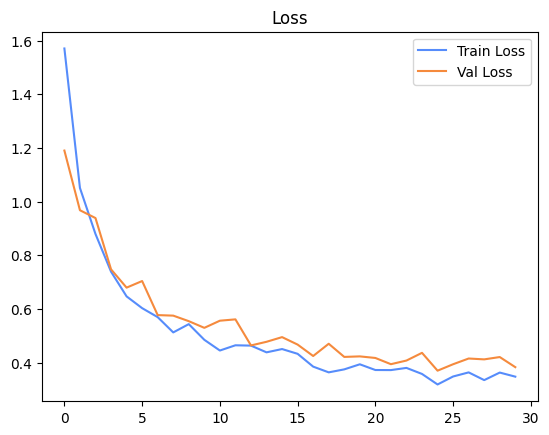

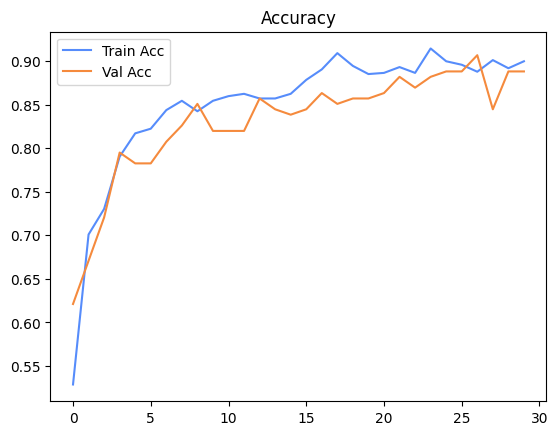

In [7]:
# 7. Curvas de 03.entrenamiento
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Val Loss")
plt.legend()
plt.title("Loss")
plt.show()

plt.plot(train_accs, label="Train Acc")
plt.plot(val_accs, label="Val Acc")
plt.legend()
plt.title("Accuracy")
plt.show()

Test Acc: 0.8571
              precision    recall  f1-score   support

     clase01       1.00      0.75      0.86         4
     clase02       0.50      0.14      0.22         7
     clase03       0.83      0.91      0.87        11
     clase05       0.70      0.88      0.78         8
     clase06       0.80      0.50      0.62         8
     clase07       0.86      0.86      0.86         7
     clase08       0.84      1.00      0.91        42
     clase09       0.33      0.33      0.33         3
     clase10       0.98      0.89      0.93        53
     clase11       0.81      0.94      0.87        18

    accuracy                           0.86       161
   macro avg       0.77      0.72      0.72       161
weighted avg       0.85      0.86      0.85       161



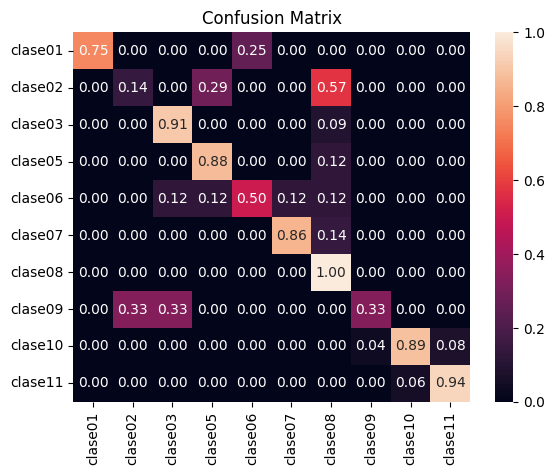

In [10]:
# 8. Evaluación final
_, test_acc, final_preds, final_labels = validate(model, test_loader)
print(f"Test Acc: {test_acc:.4f}")

all_label_ids = list(range(NUM_CLASSES))

print(
    classification_report(
        final_labels,
        final_preds,
        labels=all_label_ids,
        target_names=class_names,
        zero_division=0,
    )
)

cm = confusion_matrix(final_labels, final_preds, labels=all_label_ids, normalize='true')
sns.heatmap(cm, annot=True, fmt=".2f", xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix")
plt.show()

In [9]:
# 9. Guardado del modelo
torch.save(model.state_dict(), PATHS.OUTPUT_MODELS / f"{MODEL_NAME}_final.pth")